In [1]:
########## 1. 설정: anaconda3 ##########
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multitest import multipletests
# 기존 anaconda3의 pandas/statsmodels 버전 차이만 메모리에서 보완
try:
    from statsmodels.tsa.stattools import adfuller, grangercausalitytests
except TypeError as error:
    if 'new_arg_name' not in str(error):
        raise
    from functools import partial
    import statsmodels.compat.pandas as sm_compat
    sm_compat.deprecate_kwarg = partial(sm_compat.deprecate_kwarg, FutureWarning)
    from statsmodels.tsa.stattools import adfuller, grangercausalitytests

BASE_YEAR = 2018
MIN_TRADES = 5  # 구별 월 5건 미만은 제외
MAX_LAG = 3  # 짧은 기간의 과적합을 줄이기 위해 1~3개월 검정
TIERS = [f'{i}급지' for i in range(1, 6)]  # 1급지가 가장 높은 가격
COLORS = dict(zip(TIERS, ['#d62728', '#ff7f0e', '#bc9b00', '#2ca02c', '#1f77b4']))
for name in ['AppleGothic', 'Malgun Gothic', 'NanumGothic']:
    if name in {f.name for f in font_manager.fontManager.ttflist}:
        plt.rcParams['font.family'] = name
        break
plt.rcParams.update({'axes.unicode_minus': False, 'figure.figsize': (13, 5), 'figure.dpi': 110})
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
########## 2. 폴더 내 실거래가만 사용 ##########
filename = '서울_아파트_매매_실거래가_2017-2026_통합.xlsx'
root = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / filename).exists()), None)
if root is None:
    raise FileNotFoundError('프로젝트 폴더에서 실행하세요.')
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Workbook contains no default style')
    raw = pd.read_excel(root / filename, dtype=str)
df = raw.copy()
for col in df.columns:
    df[col] = df[col].astype('string').str.strip()
def numeric(s):
    return pd.to_numeric(s.str.replace(',', '', regex=False), errors='coerce').astype(float)
df['가격'] = numeric(df['거래금액(만원)'])
df['면적'] = numeric(df['전용면적(㎡)'])
ym = numeric(df['계약년월']).astype('Int64').astype('string')
day = numeric(df['계약일']).astype('Int64').astype('string').str.zfill(2)
df['날짜'] = pd.to_datetime(ym + day, format='%Y%m%d', errors='coerce')
df['자치구'] = df['시군구'].str.extract(r'^서울특별시\s+(\S+구)(?:\s|$)', expand=False)
valid = (df['자치구'].notna() & df['주택유형'].eq('아파트')
         & df['해제사유발생일'].fillna('').isin(['', '-', '0'])
         & df['날짜'].notna() & df['가격'].gt(0) & df['면적'].gt(0))
df = df.loc[valid.fillna(False)].copy()
df['월'] = df['날짜'].dt.to_period('M').dt.to_timestamp()
df['㎡당가격'] = df['가격'] / df['면적']
print(f"유효 거래 {len(df):,}건 / {df['날짜'].min():%Y-%m-%d} ~ {df['날짜'].max():%Y-%m-%d}")

유효 거래 530,129건 / 2017-10-28 ~ 2026-10-26


기간 전체 상승과 매달 상승은 다름. 상승률이 음수인 달도 그대로 포함.
사용자가 지정한 두 기간의 비교이며, 전체 시장에 일반화하지 않음.


,기간,기준월,종료월,시작가격_만원m2,종료가격_만원m2,누적변화_pct,상승월비율_pct,최대낙폭_pct,기간판정
0,2019~2021,2018-12,2021-12,707.760,"1,240.270",75.240,66.670,-17.060,기간 전체 상승
1,2024~2026-09,2023-12,2026-09,"1,181.800","1,353.180",14.500,54.550,-24.570,기간 전체 상승


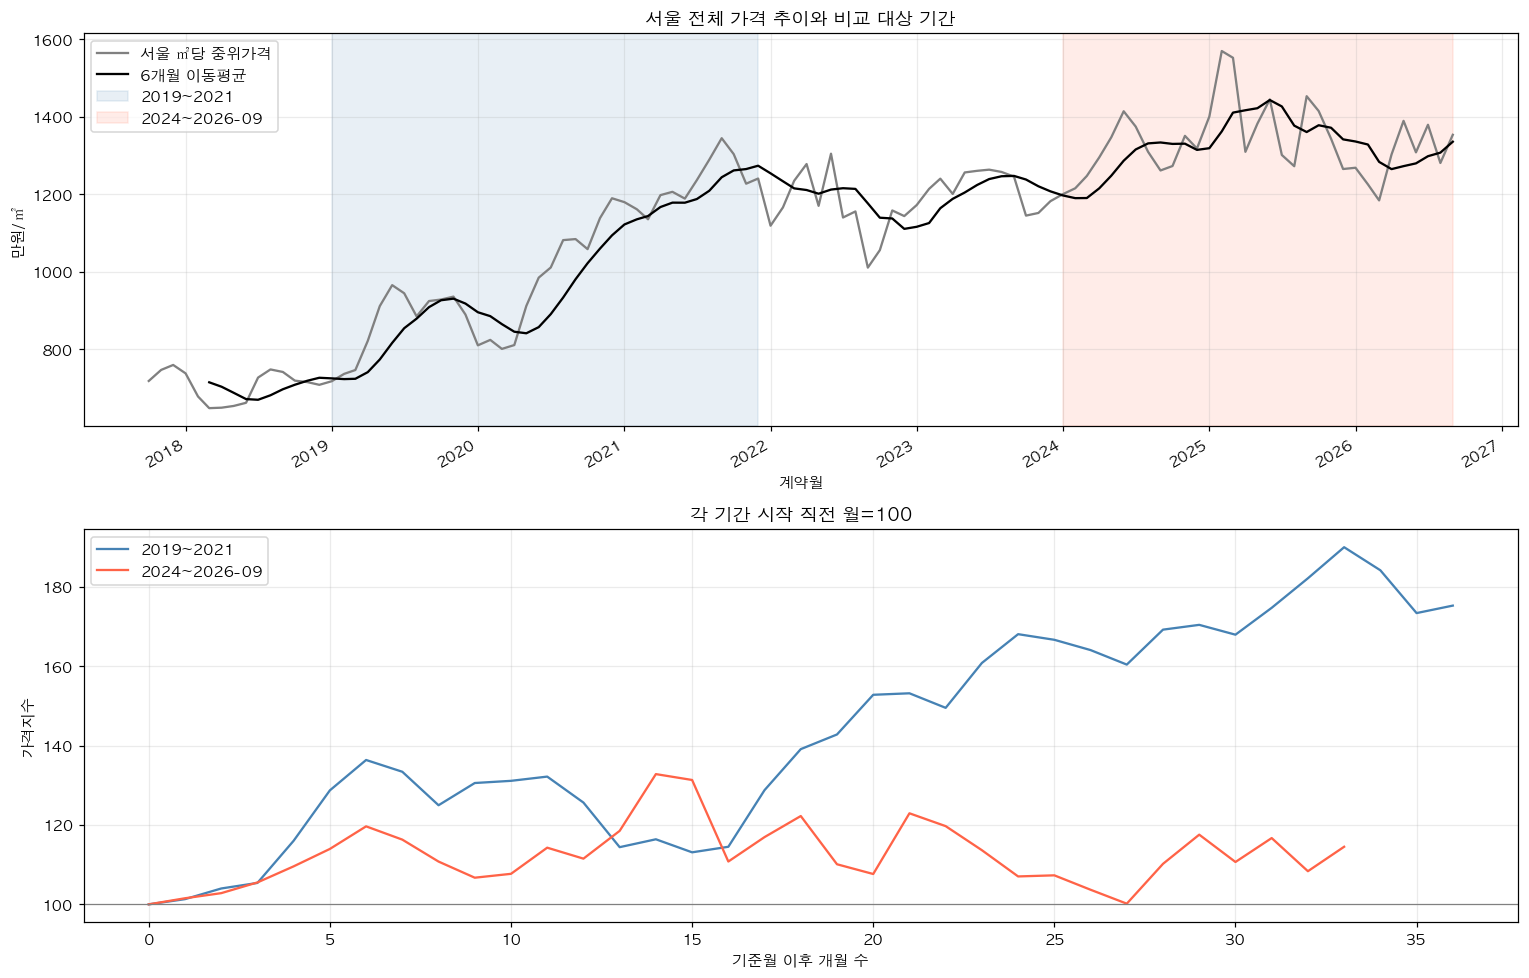

In [3]:
########## 3. 먼저 서울 전체가 상승했는지 확인 ##########
# 전체 거래의 ㎡당 중위가격. 거래 구성 변화가 포함된 지표
market = df.groupby('월')['㎡당가격'].median().asfreq('MS')
analysis_end = market.index.max() - pd.DateOffset(months=1)
periods = [('2019~2021', pd.Timestamp('2019-01-01'), pd.Timestamp('2021-12-01')),
           ('2024~' + analysis_end.strftime('%Y-%m'), pd.Timestamp('2024-01-01'), analysis_end)]
market_rows = []
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
market.loc[:analysis_end].plot(ax=axes[0], color='gray', label='서울 ㎡당 중위가격', x_compat=True)
market.rolling(6, min_periods=6).mean().loc[:analysis_end].plot(
    ax=axes[0], color='black', label='6개월 이동평균', x_compat=True)
for (label, a, b), color in zip(periods, ['steelblue', 'tomato']):
    baseline = a - pd.DateOffset(months=1)
    s = market.loc[baseline:b]
    if baseline not in s.index or pd.isna(s.loc[baseline]) or b not in s.index:
        raise ValueError(f'{label}: 기간 시작·종료 가격이 없습니다.')
    changes = s.pct_change(fill_method=None).loc[a:b] * 100
    index = s / s.loc[baseline] * 100
    cumulative = (s.loc[b] / s.loc[baseline] - 1) * 100
    drawdown = (s / s.cummax() - 1).min() * 100
    market_rows.append({'기간': label, '기준월': baseline.strftime('%Y-%m'), '종료월': b.strftime('%Y-%m'),
        '시작가격_만원m2': s.loc[baseline], '종료가격_만원m2': s.loc[b],
        '누적변화_pct': cumulative, '상승월비율_pct': changes.gt(0).sum() / changes.notna().sum() * 100,
        '최대낙폭_pct': drawdown, '기간판정': '기간 전체 상승' if cumulative > 0 else '기간 전체 비상승'})
    axes[0].axvspan(a, b, color=color, alpha=0.12, label=label)
    axes[1].plot(np.arange(len(index)), index, label=label, color=color)
market_summary = pd.DataFrame(market_rows)
display(market_summary.round(2))
axes[0].set(title='서울 전체 가격 추이와 비교 대상 기간', ylabel='만원/㎡', xlabel='계약월')
axes[1].set(title='각 기간 시작 직전 월=100', ylabel='가격지수', xlabel='기준월 이후 개월 수')
axes[1].axhline(100, color='gray', linewidth=0.8)
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()
print('기간 전체 상승과 매달 상승은 다름. 상승률이 음수인 달도 그대로 포함.')
print('사용자가 지정한 두 기간의 비교이며, 전체 시장에 일반화하지 않음.')

단위: 만원/㎡ / 급지는 이후 기간에도 고정
군집 분리도: 0.493
분위수 분류와 일치도(ARI): 0.496


/opt/anaconda3/lib/python3.13/site-packages/joblib/externals/loky/backend/context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
invalid literal for int() with base 10: ''
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/opt/anaconda3/lib/python3.13/site-packages/joblib/externals/loky/backend/context.py", line 249, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
  File "/opt/anaconda3/lib/python3.13/site-packages/joblib/externals/loky/backend/context.py", line 318, in _count_physical_cores_darwin
    return int(cpu_info)


,기준가격,기준거래량,급지,분위수급지
자치구,,,,
강남구,"1,638.500",3529,1급지,1급지
서초구,"1,284.300",3106,1급지,1급지
용산구,"1,143.300",1717,2급지,1급지
송파구,"1,059.400",4603,2급지,1급지
성동구,"1,000.800",2879,2급지,1급지
광진구,966.700,1462,2급지,2급지
마포구,949.000,2941,2급지,2급지
동작구,858.500,2769,3급지,2급지
중구,854.900,1277,3급지,2급지


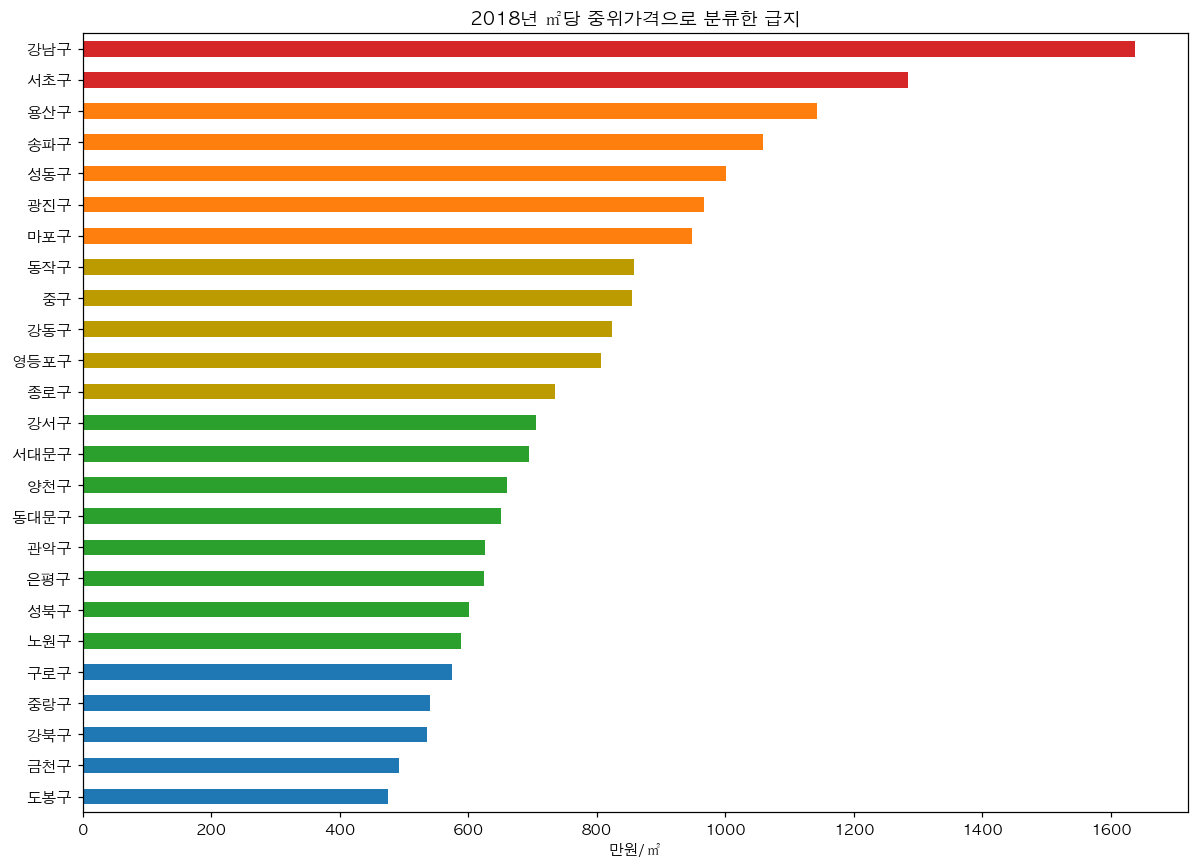

In [4]:
########## 4. 2018년 가격으로 5개 급지 고정 ##########
# 가격 수준의 분류이며, 주거환경 평가나 가격 원인 변수는 아님
base = df[df['날짜'].dt.year.eq(BASE_YEAR)].groupby('자치구').agg(
    기준가격=('㎡당가격', 'median'), 기준거래량=('㎡당가격', 'size'))
assert len(base) == 25, '기준연도에 서울 25개 구가 모두 있어야 합니다.'
X = np.log(base[['기준가격']].to_numpy())
model = KMeans(n_clusters=len(TIERS), random_state=42, n_init=30).fit(X)
order = np.argsort(model.cluster_centers_.ravel())[::-1]
names = dict(zip(order, TIERS))
base['급지'] = [names[x] for x in model.labels_]
base['분위수급지'] = pd.qcut(base['기준가격'], len(TIERS), labels=TIERS[::-1])
display(base.sort_values('기준가격', ascending=False).round(1))
print('단위: 만원/㎡ / 급지는 이후 기간에도 고정')
print(f'군집 분리도: {silhouette_score(X, model.labels_):.3f}')
print(f'분위수 분류와 일치도(ARI): {adjusted_rand_score(base["급지"], base["분위수급지"]):.3f}')
ax = base.sort_values('기준가격')['기준가격'].plot.barh(
    figsize=(11, 8), color=base.sort_values('기준가격')['급지'].map(COLORS))
ax.set(title='2018년 ㎡당 중위가격으로 분류한 급지', xlabel='만원/㎡', ylabel='')
plt.tight_layout()
plt.show()

In [5]:
########## 5. 구별 상승률을 동일 비중으로 평균 ##########
prices = df.groupby(['월', '자치구'])['㎡당가격'].median().unstack().asfreq('MS')
counts = df.groupby(['월', '자치구']).size().unstack().reindex(prices.index).fillna(0)
prices = prices.where(counts >= MIN_TRADES)
returns_gu = prices.pct_change(fill_method=None) * 100
yoy_gu = prices.pct_change(12, fill_method=None) * 100
start = pd.Timestamp(BASE_YEAR + 1, 1, 1)
end = prices.index.max() - pd.DateOffset(months=1)  # 마지막 달 부분 집계 제외

def aggregate_tiers(values, labels):
    result = {}
    for tier in TIERS:
        members = labels.index[labels.eq(tier)]
        part = values.reindex(columns=members)
        # 구성 구가 하나라도 빠진 달은 결측 유지
        result[tier] = part.mean(axis=1).where(part.notna().all(axis=1))
    return pd.DataFrame(result).loc[start:end]

returns = aggregate_tiers(returns_gu, base['급지'])
yoy = aggregate_tiers(yoy_gu, base['급지'])
quantile_returns = aggregate_tiers(returns_gu, base['분위수급지'])
coverage = pd.DataFrame({'구 수': base['급지'].value_counts(),
                         '유효 월': returns.notna().sum(), '결측 월': returns.isna().sum()}).reindex(TIERS)
display(coverage)
print(f'분석: {start:%Y-%m} ~ {end:%Y-%m}; 결측월은 보간하지 않음')
display(returns.tail(6).round(2))

분석: 2019-01 ~ 2026-09; 결측월은 보간하지 않음


,구 수,유효 월,결측 월
1급지,2,93,0
2급지,5,93,0
3급지,5,91,2
4급지,8,93,0
5급지,5,93,0


,1급지,2급지,3급지,4급지,5급지
월,,,,,
2026-04-01,23.240,9.650,2.340,1.870,1.640
2026-05-01,5.190,-3.500,1.420,4.620,5.040
2026-06-01,-8.880,-0.960,6.850,1.490,-4.400
2026-07-01,-2.650,5.320,-3.410,3.940,9.550
2026-08-01,-1.810,-6.300,6.810,-3.250,-4.930
2026-09-01,12.060,1.730,-1.390,2.840,-2.090


전년 동월 대비는 비교 기준이 기간 밖일 수 있음. 검정은 기간 내 월별 상승률 사용.


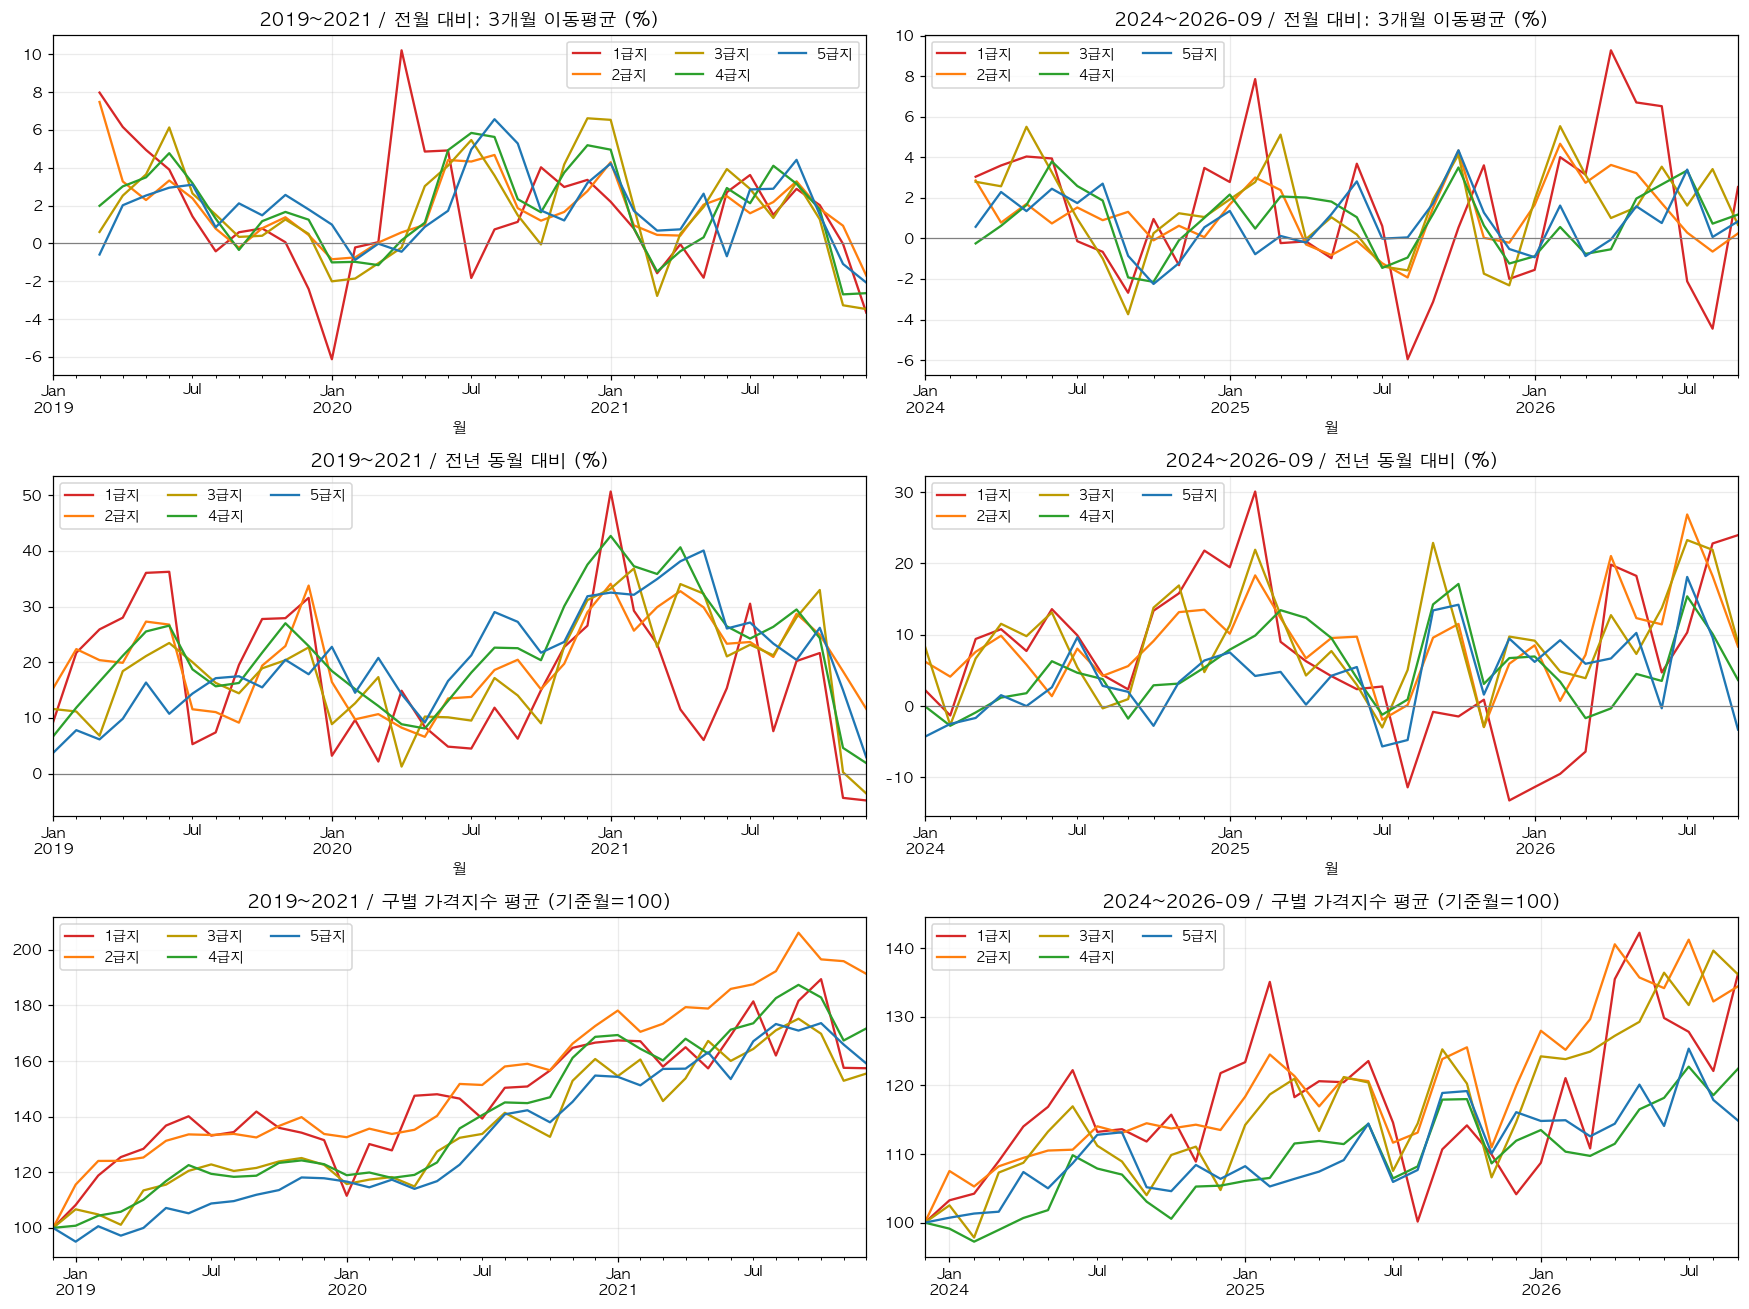

,기간,급지,누적변화_pct,월평균상승률_pct,유효월
0,2019~2021,1급지,57.410,1.660,36
1,2019~2021,2급지,91.370,2.060,36
2,2019~2021,3급지,55.490,1.640,36
3,2019~2021,4급지,71.720,1.750,36
4,2019~2021,5급지,59.140,1.570,36
5,2024~2026-09,1급지,36.240,1.660,33
6,2024~2026-09,2급지,34.440,1.200,33
7,2024~2026-09,3급지,36.170,1.420,33
8,2024~2026-09,4급지,22.430,0.800,33
9,2024~2026-09,5급지,14.870,0.690,33


In [6]:
########## 6. 두 기간의 급지별 상승률을 따로 비교 ##########
# 각 기간 내부에서만 이동평균 계산. 가격지수는 시작 직전 월=100
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
period_tier_rows = []
for col, (label, a, b) in enumerate(periods):
    baseline = a - pd.DateOffset(months=1)
    normalized = prices.div(prices.loc[baseline]) * 100
    indices = aggregate_tiers(normalized, base['급지'])
    for tier in TIERS:
        s = returns.loc[a:b, tier]
        s.rolling(3, min_periods=3).mean().plot(ax=axes[0, col], label=tier, color=COLORS[tier])
        yoy.loc[a:b, tier].plot(ax=axes[1, col], label=tier, color=COLORS[tier])
        idx = pd.concat([pd.Series([100.0], index=[baseline]), indices.loc[a:b, tier]])
        idx.plot(ax=axes[2, col], label=tier, color=COLORS[tier])
        period_tier_rows.append({'기간': label, '급지': tier, '누적변화_pct': idx.loc[b] - 100,
                                '월평균상승률_pct': s.mean(), '유효월': s.notna().sum()})
    for row, title in enumerate(['전월 대비: 3개월 이동평균 (%)', '전년 동월 대비 (%)', '구별 가격지수 평균 (기준월=100)']):
        axes[row, col].set_title(label + ' / ' + title)
        axes[row, col].grid(alpha=0.25)
        axes[row, col].legend(ncol=3, fontsize=9)
    for row in [0, 1]:
        axes[row, col].axhline(0, color='gray', linewidth=0.8)
plt.tight_layout()
plt.show()
period_tier_summary = pd.DataFrame(period_tier_rows)
display(period_tier_summary.round(2))
print('전년 동월 대비는 비교 기준이 기간 밖일 수 있음. 검정은 기간 내 월별 상승률 사용.')

상대 상승=(1급지 가격지수÷5급지 가격지수−1)×100. 가격 수준의 절대 격차와는 다름.


,기간,급지,월평균상승률_pct,월복리환산_pct,누적변화_pct
0,2019~2021,1급지,1.660,1.270,57.410
1,2019~2021,2급지,2.060,1.820,91.370
2,2019~2021,3급지,1.640,1.230,55.490
3,2019~2021,4급지,1.750,1.510,71.720
4,2019~2021,5급지,1.570,1.300,59.140
5,2024~2026-09,1급지,1.660,0.940,36.240
6,2024~2026-09,2급지,1.200,0.900,34.440
7,2024~2026-09,3급지,1.420,0.940,36.170
8,2024~2026-09,4급지,0.800,0.620,22.430
9,2024~2026-09,5급지,0.690,0.420,14.870


,기간,개월수,1급지누적_pct,5급지누적_pct,1−5급지격차_pp,1급지상대상승_pct,5개급지최대최소차_pp
0,2019~2021,36,57.410,59.140,-1.720,-1.080,35.880
1,2024~2026-09,33,36.240,14.870,21.370,18.600,21.370


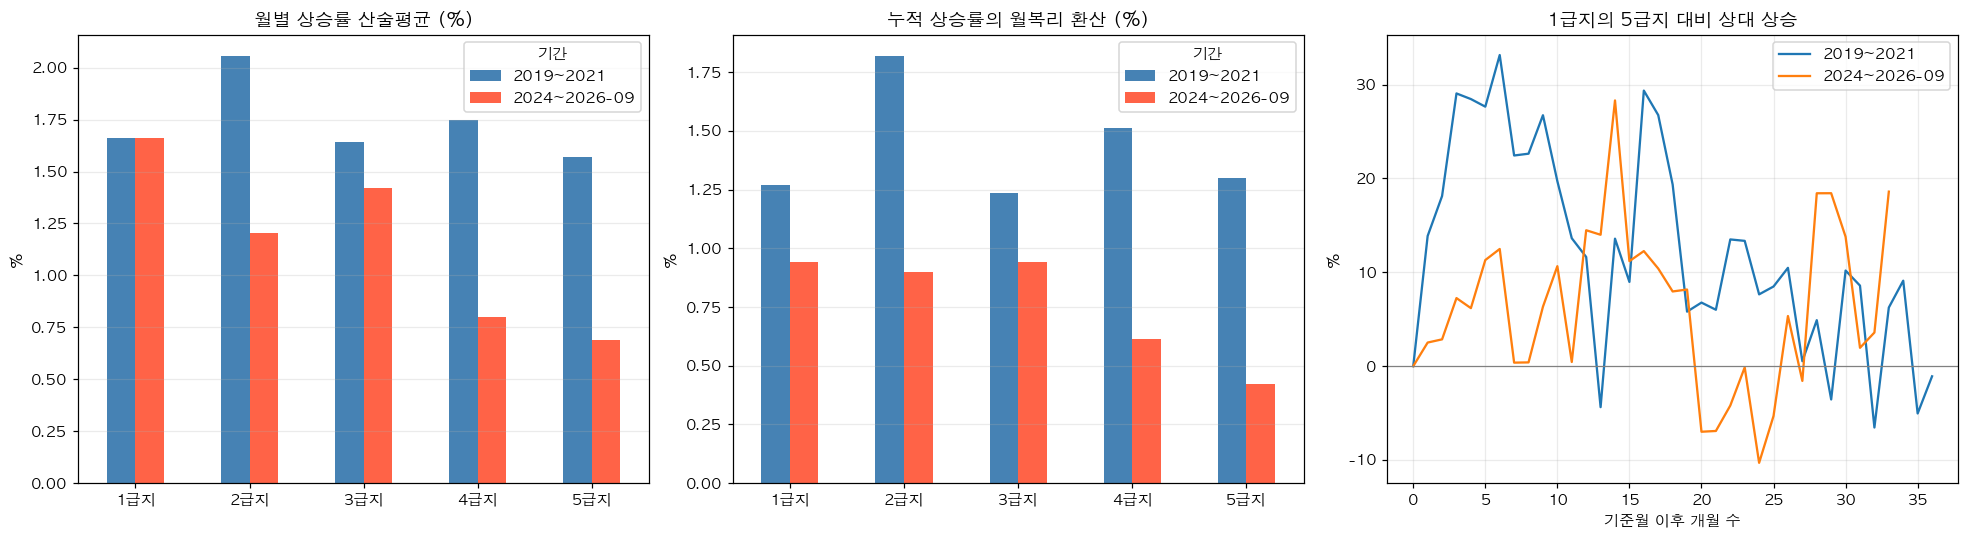

,기간,비교개월수,종료월,1급지누적_pct,5급지누적_pct,1−5급지격차_pp
0,2019~2021,33,2021-09,81.640,70.960,10.680
1,2024~2026-09,33,2026-09,36.240,14.870,21.370


In [7]:
########## 7. 급지별 상승 폭과 격차 비교 ##########
# 월평균은 산술평균이며 복리 수익률이 아님. 기간 길이도 함께 표시
gap_rows, relative_paths = [], {}
for label, a, b in periods:
    baseline = a - pd.DateOffset(months=1)
    normalized = prices.div(prices.loc[baseline]) * 100
    indices = aggregate_tiers(normalized, base['급지']).loc[a:b]
    months = len(indices)
    final = indices.loc[b] - 100
    ratio = (indices['1급지'] / indices['5급지'] - 1) * 100
    relative_paths[label] = pd.concat([pd.Series([0.0]), ratio.reset_index(drop=True)], ignore_index=True)
    gap_rows.append({'기간': label, '개월수': months,
        '1급지누적_pct': final['1급지'], '5급지누적_pct': final['5급지'],
        '1−5급지격차_pp': final['1급지'] - final['5급지'],
        '1급지상대상승_pct': ratio.loc[b],
        '5개급지최대최소차_pp': final.max() - final.min()})
gap_summary = pd.DataFrame(gap_rows)
comparison_summary = period_tier_summary.copy()
comparison_summary['월복리환산_pct'] = (
    (1 + comparison_summary['누적변화_pct'] / 100)
    ** (1 / comparison_summary['기간'].map(gap_summary.set_index('기간')['개월수'])) - 1) * 100
display(comparison_summary[['기간', '급지', '월평균상승률_pct', '월복리환산_pct', '누적변화_pct']].round(2))
display(gap_summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric, title in zip(axes[:2], ['월평균상승률_pct', '월복리환산_pct'],
                           ['월별 상승률 산술평균 (%)', '누적 상승률의 월복리 환산 (%)']):
    table = comparison_summary.pivot(index='급지', columns='기간', values=metric).reindex(TIERS)
    table.plot.bar(ax=ax, rot=0, color=['steelblue', 'tomato'])
    ax.set(title=title, xlabel='', ylabel='%')
    ax.grid(axis='y', alpha=0.25)
for label, path in relative_paths.items():
    axes[2].plot(path.index, path, label=label)
axes[2].axhline(0, color='gray', linewidth=0.8)
axes[2].set(title='1급지의 5급지 대비 상대 상승', xlabel='기준월 이후 개월 수', ylabel='%')
axes[2].legend()
axes[2].grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 기간 길이가 다르므로 시작 후 동일 개월 수에서도 확인
common_months = int(gap_summary['개월수'].min())
same_horizon = []
for label, a, b in periods:
    baseline = a - pd.DateOffset(months=1)
    endpoint = a + pd.DateOffset(months=common_months - 1)
    normalized = prices.div(prices.loc[baseline]) * 100
    final = aggregate_tiers(normalized, base['급지']).loc[endpoint] - 100
    same_horizon.append({'기간': label, '비교개월수': common_months, '종료월': endpoint.strftime('%Y-%m'),
                         '1급지누적_pct': final['1급지'], '5급지누적_pct': final['5급지'],
                         '1−5급지격차_pp': final['1급지'] - final['5급지']})
display(pd.DataFrame(same_horizon).round(2))
print('상대 상승=(1급지 가격지수÷5급지 가격지수−1)×100. 가격 수준의 절대 격차와는 다름.')

In [8]:
########## 8. 핵심 해석: 시기에 따라 상승의 분포가 달라짐 ##########
first_label, recent_label = periods[0][0], periods[1][0]
first = comparison_summary[comparison_summary['기간'].eq(first_label)].set_index('급지')
recent = comparison_summary[comparison_summary['기간'].eq(recent_label)].set_index('급지')
print('1급지 구성:', ', '.join(base.index[base['급지'].eq('1급지')]))
for label, table in [(first_label, first), (recent_label, recent)]:
    print(f"{label}: 월평균 상승률 {table['월평균상승률_pct'].min():.2f}~{table['월평균상승률_pct'].max():.2f}%.")
    print(' / '.join(f"{t} 누적 {table.loc[t, '누적변화_pct']:+.2f}%" for t in TIERS))
latest_gap = gap_summary.iloc[-1]
print(f"최근 1−5급지 누적 상승률 차이: {latest_gap['1−5급지격차_pp']:+.2f}%p.")
if (first['누적변화_pct'] > 0).all():
    print('과거에는 전 급지가 동반 상승.')
if recent.loc['1급지', '누적변화_pct'] > recent.loc['5급지', '누적변화_pct']:
    print('최근에는 1급지가 5급지보다 높은 누적 상승률을 보임.')
else:
    print('최근에는 1급지의 5급지 대비 상승 우위가 확인되지 않음.')
old_spread, new_spread = gap_summary['5개급지최대최소차_pp'].iloc[[0, -1]]
print(f'전체 급지 누적 상승률의 최대·최소 차이: 과거 {old_spread:.2f}%p → 최근 {new_spread:.2f}%p.')
print('기간 길이는 동일 개월 수 비교표로 함께 확인. 2018년 급지를 고정한 기술적 비교이며 인과관계는 아님.')

1급지 구성: 강남구, 서초구
2019~2021: 월평균 상승률 1.57~2.06%.
1급지 누적 +57.41% / 2급지 누적 +91.37% / 3급지 누적 +55.49% / 4급지 누적 +71.72% / 5급지 누적 +59.14%
2024~2026-09: 월평균 상승률 0.69~1.66%.
1급지 누적 +36.24% / 2급지 누적 +34.44% / 3급지 누적 +36.17% / 4급지 누적 +22.43% / 5급지 누적 +14.87%
최근 1−5급지 누적 상승률 차이: +21.37%p.
과거에는 전 급지가 동반 상승.
최근에는 1급지가 5급지보다 높은 누적 상승률을 보임.
전체 급지 누적 상승률의 최대·최소 차이: 과거 35.88%p → 최근 21.37%p.
기간 길이는 동일 개월 수 비교표로 함께 확인. 2018년 급지를 고정한 기술적 비교이며 인과관계는 아님.


In [9]:
########## 9. 보조 분석 / 연도별 급지 차이: Welch ANOVA ##########
# 표본은 구별 12월 대비 상승률. 월별 자료를 독립 표본으로 넣지 않음
annual_rows, welch_rows, skipped_rows = [], [], []
for year in range(BASE_YEAR + 1, end.year + 1):
    prev, curr = pd.Timestamp(year - 1, 12, 1), pd.Timestamp(year, 12, 1)
    if curr > end or prev not in prices.index or curr not in prices.index:
        continue
    if not any(a <= pd.Timestamp(year, 1, 1) and curr <= b for _, a, b in periods):
        continue
    values = (prices.loc[curr] / prices.loc[prev] - 1) * 100
    groups = [values.reindex(base.index[base['급지'].eq(t)]).dropna().to_numpy() for t in TIERS]
    for tier, g in zip(TIERS, groups):
        annual_rows.append({'연도': year, '급지': tier, '평균상승률_pct': np.mean(g), '구수': len(g)})
    if min(map(len, groups)) >= 2:
        result = anova_oneway(groups, use_var='unequal', welch_correction=True)
        welch_rows.append({'연도': year, 'F': result.statistic, 'p': result.pvalue})
    else:
        skipped_rows.append({'연도': year, '생략사유': '구별 표본 2개 미만: ' + ', '.join(t for t, g in zip(TIERS, groups) if len(g) < 2)})
annual = pd.DataFrame(annual_rows)
welch = pd.DataFrame(welch_rows)
display(annual.pivot(index='연도', columns='급지', values='평균상승률_pct').reindex(columns=TIERS).round(2))
if skipped_rows:
    display(pd.DataFrame(skipped_rows))
if not welch.empty:
    welch['보정p'] = multipletests(welch['p'], method='fdr_bh')[1]
    welch['차이유의'] = welch['보정p'] < 0.05
    display(welch.round(4))
print('연도별 탐색 검정. 구 사이의 공간적 연관성과 적은 표본 수에 유의.')
print('두 비교 기간에 포함되는 완결 연도만 비교. 진행 중인 연도는 제외.')

연도별 탐색 검정. 구 사이의 공간적 연관성과 적은 표본 수에 유의.
두 비교 기간에 포함되는 완결 연도만 비교. 진행 중인 연도는 제외.


급지,1급지,2급지,3급지,4급지,5급지
연도,,,,,
2019,31.560,33.770,22.670,22.900,17.850
2020,26.570,29.000,31.150,37.520,31.850
2021,-4.810,11.640,-3.560,1.900,2.960
2024,21.790,13.500,4.750,5.390,6.380
2025,-13.240,5.930,9.730,6.720,9.450


,연도,F,p,보정p,차이유의
0,2019,4.206,0.033,0.163,False
1,2020,0.386,0.811,0.811,False
2,2021,2.306,0.183,0.380,False
3,2024,1.978,0.228,0.380,False
4,2025,0.402,0.801,0.811,False


최대 상관 시차는 탐색 결과이며 유의한 선행 관계의 증명은 아님.


,기간,대상,시차,상관,표본월
5,2019~2021,2급지,2,0.411,34
13,2019~2021,3급지,3,0.458,33
17,2019~2021,4급지,0,0.366,36
27,2019~2021,5급지,3,0.344,33
30,2024~2026-09,2급지,-1,0.320,32
37,2024~2026-09,3급지,-1,0.341,32
48,2024~2026-09,4급지,3,0.361,30
55,2024~2026-09,5급지,3,0.469,30


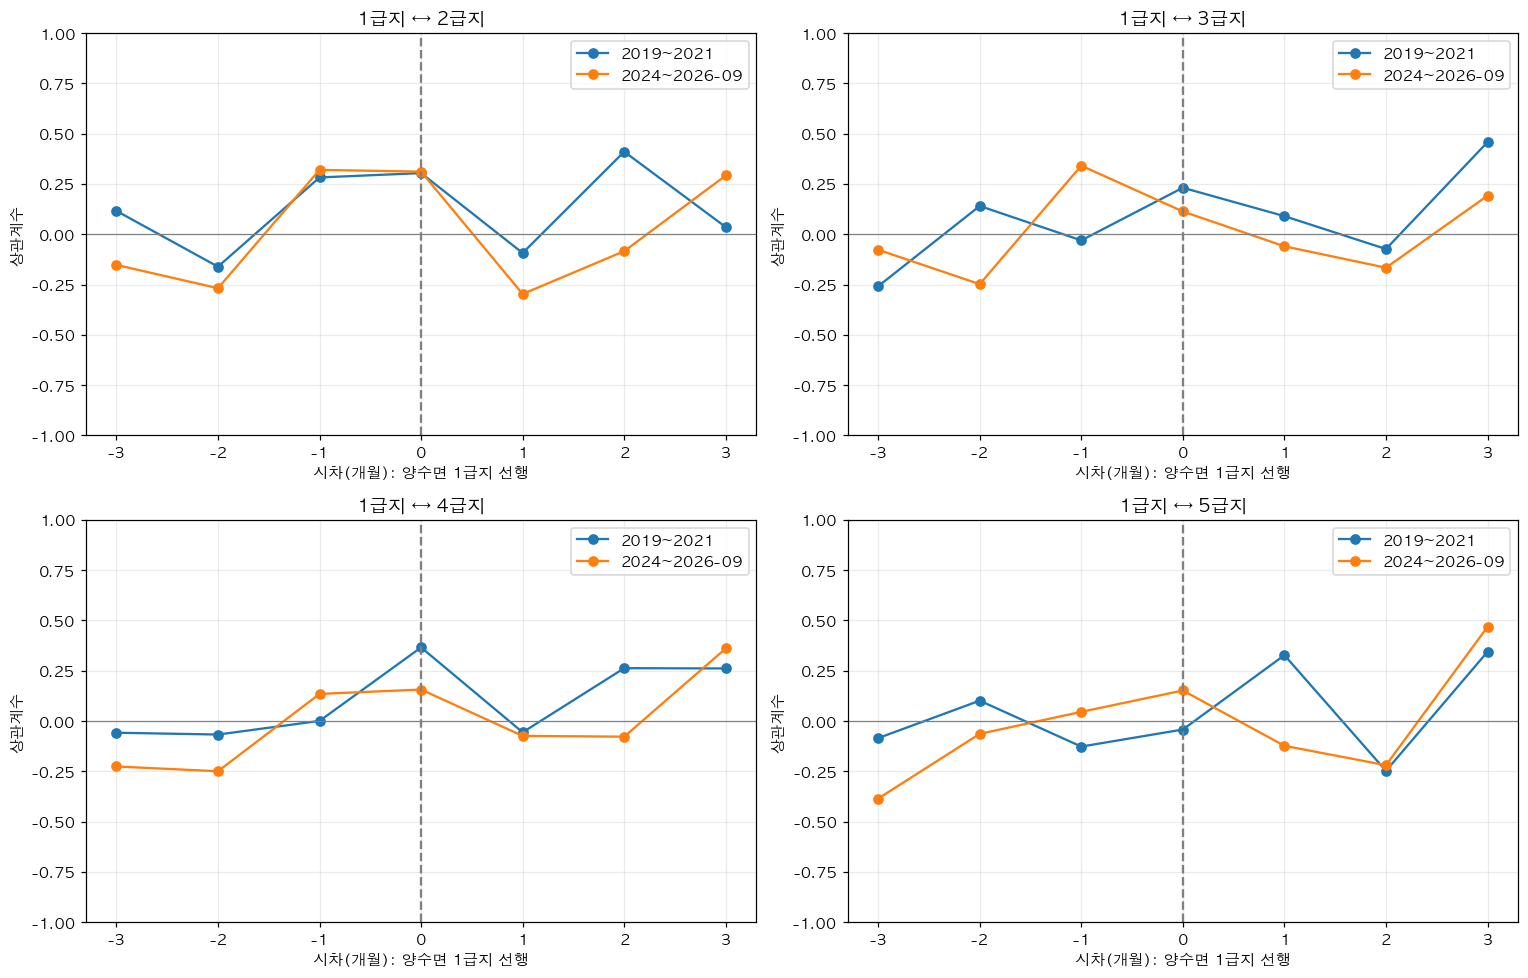

In [10]:
########## 10. 보조 분석 / 시차 상관: 1급지가 먼저 움직이는가 ##########
# 양수 시차: 1급지(t)와 다른 급지(t+시차). 음수는 반대 방향
def lag_table(data):
    rows = []
    for period, a, b in periods:
        sub = data.loc[a:b]
        for target in TIERS[1:]:
            for lag in range(-MAX_LAG, MAX_LAG + 1):
                pair = pd.concat([sub['1급지'], sub[target].shift(-lag)], axis=1).dropna()
                corr = pair.iloc[:, 0].corr(pair.iloc[:, 1]) if len(pair) >= 18 else np.nan
                rows.append({'기간': period, '대상': target, '시차': lag, '상관': corr, '표본월': len(pair)})
    return pd.DataFrame(rows)

lag_results = lag_table(returns)
best = lag_results.dropna(subset=['상관']).sort_values('상관', ascending=False).groupby(['기간', '대상'], sort=False).head(1)
display(best.sort_values(['기간', '대상']).round(3))
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, target in zip(axes.flat, TIERS[1:]):
    for period, _, _ in periods:
        s = lag_results[(lag_results['대상'] == target) & (lag_results['기간'] == period)]
        ax.plot(s['시차'], s['상관'], marker='o', label=period)
    ax.axvline(0, color='gray', linestyle='--')
    ax.axhline(0, color='gray', linewidth=0.8)
    ax.set(title=f'1급지 ↔ {target}', xlabel='시차(개월): 양수면 1급지 선행', ylabel='상관계수', ylim=(-1, 1))
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print('최대 상관 시차는 탐색 결과이며 유의한 선행 관계의 증명은 아님.')

In [11]:
########## 11. 보조 분석 / 기간별 Granger: 양방향·1~3개월 ##########
def longest_complete(data):
    ok = data.notna().all(axis=1)
    blocks = (~ok).cumsum()
    valid = data.loc[ok]
    if valid.empty:
        return valid
    block_id = blocks[ok].value_counts().idxmax()
    return valid.loc[blocks[ok].eq(block_id)]

adf_rows, granger_rows, skipped = [], [], []
for label, a, b in periods:
    for target in TIERS[1:]:
        pair = longest_complete(returns.loc[a:b, ['1급지', target]])
        if len(pair) < 24:
            skipped.append({'기간': label, '대상': target, '사유': '연속 24개월 미만'})
            continue
        stationary = True
        for tier in pair.columns:
            pvalue = adfuller(pair[tier], maxlag=MAX_LAG, autolag='AIC')[1]
            adf_rows.append({'기간': label, '비교대상': target, '급지': tier, 'ADF_p': pvalue,
                             '시작': pair.index.min().strftime('%Y-%m'), '종료': pair.index.max().strftime('%Y-%m'), '월수': len(pair)})
            stationary = stationary and pvalue < 0.05
        if not stationary:
            skipped.append({'기간': label, '대상': target, '사유': 'ADF 정상성 미확인'})
            continue
        for cause, effect in [('1급지', target), (target, '1급지')]:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', FutureWarning)
                tests = grangercausalitytests(pair[[effect, cause]], maxlag=MAX_LAG, verbose=False)
            for lag, test in tests.items():
                f, pvalue, _, _ = test[0]['ssr_ftest']
                granger_rows.append({'기간': label, '방향': cause + ' → ' + effect,
                                     '지연차수': lag, 'F': f, 'p': pvalue, '월수': len(pair)})
display(pd.DataFrame(adf_rows).round(4))
granger = pd.DataFrame(granger_rows)
if not granger.empty:
    # 두 기간·모든 방향·모든 지연차수의 검정을 함께 보정
    granger['보정p'] = multipletests(granger['p'], method='fdr_bh')[1]
    for label, group in granger.groupby('기간'):
        print(label)
        display(group.pivot(index='지연차수', columns='방향', values='보정p').round(4))
if skipped:
    display(pd.DataFrame(skipped))
print('보정p<0.05: 추가 예측정보. 가격 전파의 인과 증명은 아님.')
print('지연차수 3은 과거 1~3개월 공동 검정. 짧은 구간의 탐색 결과로 해석.')

2019~2021
2024~2026-09
보정p<0.05: 추가 예측정보. 가격 전파의 인과 증명은 아님.
지연차수 3은 과거 1~3개월 공동 검정. 짧은 구간의 탐색 결과로 해석.


,기간,비교대상,급지,ADF_p,시작,종료,월수
0,2019~2021,2급지,1급지,0.000,2019-01,2021-12,36
1,2019~2021,2급지,2급지,0.000,2019-01,2021-12,36
2,2019~2021,3급지,1급지,0.000,2019-01,2021-12,36
3,2019~2021,3급지,3급지,0.001,2019-01,2021-12,36
4,2019~2021,4급지,1급지,0.000,2019-01,2021-12,36
5,2019~2021,4급지,4급지,0.000,2019-01,2021-12,36
6,2019~2021,5급지,1급지,0.000,2019-01,2021-12,36
7,2019~2021,5급지,5급지,0.000,2019-01,2021-12,36
8,2024~2026-09,2급지,1급지,0.000,2024-01,2026-09,33
9,2024~2026-09,2급지,2급지,0.000,2024-01,2026-09,33


방향,1급지 → 2급지,1급지 → 3급지,1급지 → 4급지,1급지 → 5급지,2급지 → 1급지,3급지 → 1급지,4급지 → 1급지,5급지 → 1급지
지연차수,,,,,,,,
1,0.746,0.806,0.746,0.327,0.274,0.963,0.891,0.746
2,0.274,0.937,0.527,0.572,0.620,0.937,0.891,0.963
3,0.276,0.274,0.315,0.276,0.742,0.891,0.963,0.963


방향,1급지 → 2급지,1급지 → 3급지,1급지 → 4급지,1급지 → 5급지,2급지 → 1급지,3급지 → 1급지,4급지 → 1급지,5급지 → 1급지
지연차수,,,,,,,,
1,0.580,0.963,0.937,0.937,0.274,0.276,0.746,0.891
2,0.955,0.891,0.963,0.746,0.485,0.519,0.806,0.963
3,0.963,0.937,0.746,0.698,0.580,0.620,0.746,0.527


In [12]:
########## 12. 보조 분석 / 기간별 결과 요약 ##########
display(market_summary[['기간', '누적변화_pct', '상승월비율_pct', '최대낙폭_pct', '기간판정']].round(2))
q_lags = lag_table(quantile_returns)
q_best = q_lags.dropna(subset=['상관']).sort_values('상관', ascending=False).groupby(['기간', '대상']).head(1)
comparison = best[['기간', '대상', '시차', '상관']].merge(
    q_best[['기간', '대상', '시차', '상관']], on=['기간', '대상'], suffixes=('_KMeans', '_분위수'))
display(comparison.sort_values(['기간', '대상']).round(3))
if not granger.empty:
    for label, _, _ in periods:
        tested = granger[granger['기간'].eq(label)]
        significant = tested[tested['보정p'] < 0.05]
        if tested.empty:
            print(label + ': Granger 검정 가능한 조합 없음.')
        elif significant.empty:
            print(label + ': 보정 후 유의한 선행 방향 없음.')
        else:
            for direction, group in significant.groupby('방향'):
                print(f"{label}: {direction}, 유의한 지연차수 {group['지연차수'].tolist()}")
if welch.empty:
    print('Welch ANOVA: 표본 조건을 충족하지 못해 생략.')
else:
    significant_years = welch.loc[welch['차이유의'], '연도'].tolist()
    print('Welch ANOVA: 보정 후 유의한 연도', significant_years if significant_years else '없음')
print('기간·분류법에 따라 결과가 바뀌면 일관된 선행 관계로 단정하지 않음.')

2019~2021: 보정 후 유의한 선행 방향 없음.
2024~2026-09: 보정 후 유의한 선행 방향 없음.
Welch ANOVA: 보정 후 유의한 연도 없음
기간·분류법에 따라 결과가 바뀌면 일관된 선행 관계로 단정하지 않음.


,기간,누적변화_pct,상승월비율_pct,최대낙폭_pct,기간판정
0,2019~2021,75.240,66.670,-17.060,기간 전체 상승
1,2024~2026-09,14.500,54.550,-24.570,기간 전체 상승


,기간,대상,시차_KMeans,상관_KMeans,시차_분위수,상관_분위수
2,2019~2021,2급지,2,0.411,0,0.293
1,2019~2021,3급지,3,0.458,3,0.500
3,2019~2021,4급지,0,0.366,0,0.203
5,2019~2021,5급지,3,0.344,1,0.337
7,2024~2026-09,2급지,-1,0.320,3,0.399
6,2024~2026-09,3급지,-1,0.341,-1,0.258
4,2024~2026-09,4급지,3,0.361,3,0.314
0,2024~2026-09,5급지,3,0.469,3,0.458
